# Deteccion de fraude en pagos electronicos

Este notebook consume los modulos de `fraud_detection`; no duplica la logica de carga, preprocesamiento, entrenamiento ni evaluacion.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from fraud_detection.data import load_dataset, audit_and_deduplicate, stratified_split
from fraud_detection.experiment import run_experiment

ROOT = Path('..').resolve() if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
DATA = ROOT / 'data' / 'raw' / 'creditcard.csv'

## Auditoria y particiones

In [2]:
raw = load_dataset(DATA)
clean, audit = audit_and_deduplicate(raw)
splits = stratified_split(clean)
pd.DataFrame([audit.to_dict()])

,rows_original,fraud_original,missing_values,duplicate_rows,duplicate_fraud,rows_clean,fraud_clean
0,284807,492,0,1081,19,283726,473


In [3]:
pd.DataFrame({
    'conjunto': ['entrenamiento', 'validacion', 'prueba'],
    'filas': [len(splits.X_train), len(splits.X_validation), len(splits.X_test)],
    'fraudes': [int(splits.y_train.sum()), int(splits.y_validation.sum()), int(splits.y_test.sum())],
})

,conjunto,filas,fraudes
0,entrenamiento,170235,284
1,validacion,56745,94
2,prueba,56746,95


## Entrenamiento reproducible

Cambie `EJECUTAR_ENTRENAMIENTO` a `True` para regenerar modelos, metricas y figuras. Por defecto se leen los resultados ya generados.

In [4]:
EJECUTAR_ENTRENAMIENTO = False
if EJECUTAR_ENTRENAMIENTO:
    summary = run_experiment(DATA, ROOT)
else:
    summary = json.loads((ROOT / 'reports' / 'metrics' / 'resumen_experimento.json').read_text(encoding='utf-8'))
summary['selected_model']

'random_forest'

In [5]:
metricas = pd.read_csv(ROOT / 'reports' / 'metrics' / 'metricas_prueba.csv')
metricas

,model,average_precision,precision,recall,f1,accuracy,threshold,tn,fp,fn,tp
0,logistic_regression,0.725343,0.887500,0.747368,0.811429,0.999418,1.000000,56642,9,24,71
1,random_forest,0.852519,0.948718,0.778947,0.855491,0.999559,0.280000,56647,4,21,74
2,mlp,0.829057,0.791667,0.800000,0.795812,0.999313,0.988495,56631,20,19,76


## Curvas Precision-Recall y matriz de confusion

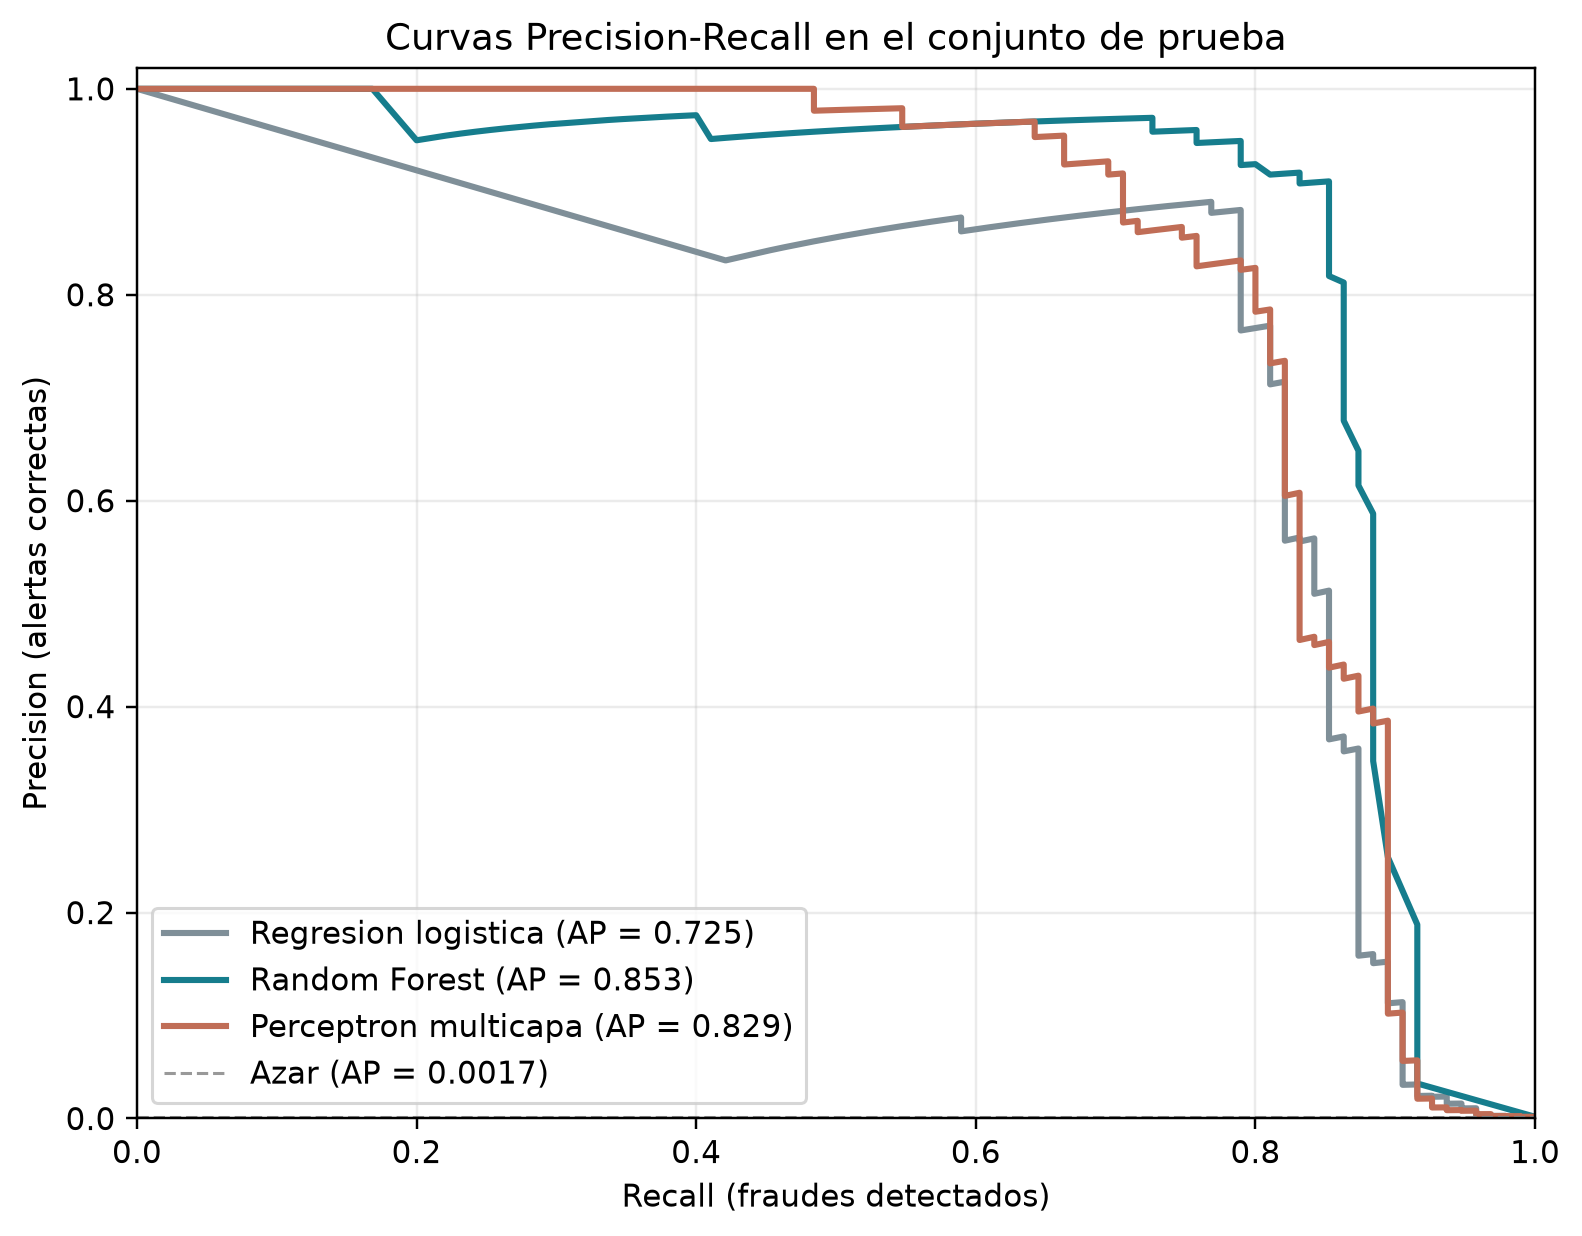

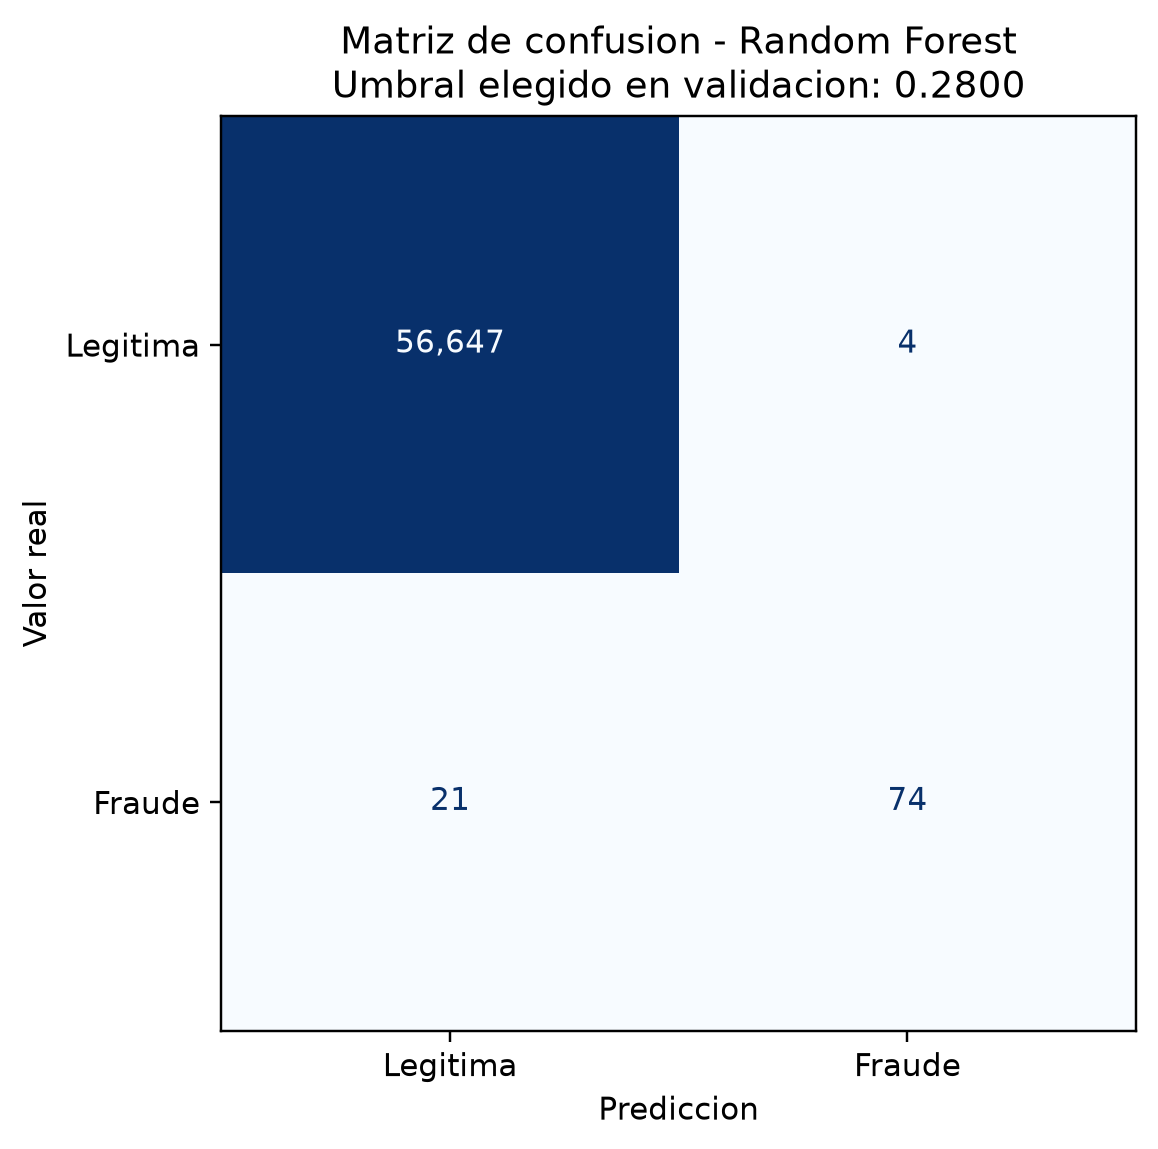

In [6]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / '03_curvas_precision_recall.png')))
display(Image(filename=str(ROOT / 'reports' / 'figures' / '04_matriz_confusion_modelo_seleccionado.png')))

## Advertencia

La salida se trata como puntaje de riesgo. No se afirma que sea una probabilidad calibrada. Esta PoC no autoriza ni bloquea pagos reales.